In [ ]:
SMS Spam Detection using Machine Learning

Project Overview

This project uses Machine Learning to classify SMS messages as Spam or Ham (Not Spam).

Dataset

UCI SMS Spam Collection Dataset.

Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

Algorithm

Multinomial Naive Bayes

Feature Extraction

TF-IDF (Term Frequency-Inverse Document Frequency).

Input

SMS Text Messages.

Target Variable

- Spam
- Ham (Not Spam)

Data Preprocessing

- Loaded the SMS dataset
- Checked and removed duplicate records
- Converted text labels into numerical values
- Transformed text messages using TF-IDF

Model Evaluation

- Accuracy Score
- Precision
- Recall
- F1-Score
- Confusion Matrix

Visualizations

- Spam and Ham Message Distribution
- Confusion Matrix Heatmap

Expected Outcome

Classify incoming SMS messages as Spam or Ham using a trained Machine Learning model.

In [ ]:
# Install and import required libraries
!pip install pandas numpy scikit-learn matplotlib seaborn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import urllib.request
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = urllib.request.urlopen(url)
z = zipfile.ZipFile(io.BytesIO(response.read()))

df = pd.read_csv(
    z.open("SMSSpamCollection"),
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Missing Values:
label      0
message    0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 5169 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5169 non-null   object
 1   message  5169 non-null   object
dtypes: object(2)
memory usage: 121.1+ KB
None

Message Counts:
label
ham     4516
spam     653
Name: count, dtype: int64


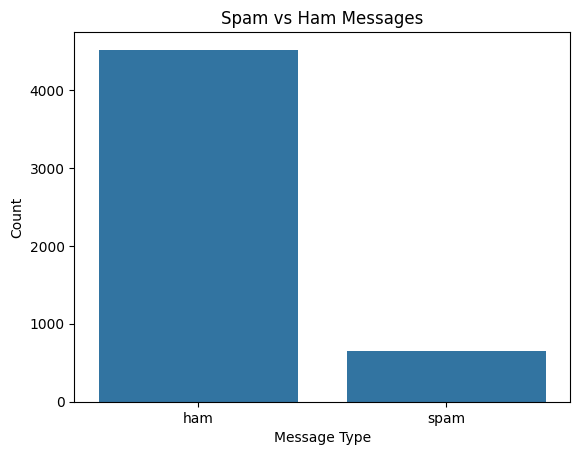

In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove duplicate messages
df = df.drop_duplicates()

# Check dataset information
print("\nDataset Information:")
print(df.info())

# Count Spam and Ham messages
print("\nMessage Counts:")
print(df["label"].value_counts())

# Visualize Spam and Ham messages
sns.countplot(data=df, x="label")
plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Count")
plt.show()

In [ ]:
# Convert labels into numbers
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

# Convert text into numerical features
tfidf = TfidfVectorizer(stop_words="english")

X = tfidf.fit_transform(df["message"])
y = df["label_num"]

print("Text converted into numerical data!")
print("Features Shape:", X.shape)
print("Labels Shape:", y.shape)

Text converted into numerical data!
Features Shape: (5169, 8444)
Labels Shape: (5169,)


In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data split successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Data split successfully!
Training samples: 4135
Testing samples: 1034


In [ ]:
# Create Naive Bayes model
model = MultinomialNB()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
# Predict test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

Model Evaluation Results
------------------------
Accuracy: 96.71 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.96      1034



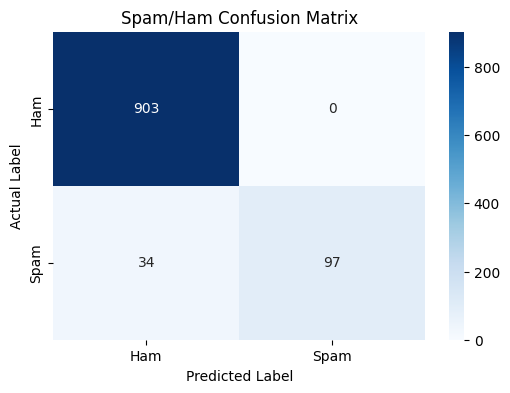

In [ ]:
# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Spam/Ham Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [ ]:
# Test messages
messages = [
    "Congratulations! You won a free prize. Call now!",
    "Hey, are you coming to college today?",
    "You have won a lottery. Claim your reward now!",
    "I will meet you tomorrow."
]

# Convert messages into numerical features
new_data = tfidf.transform(messages)

# Predict messages
predictions = model.predict(new_data)

# Display results
for msg, pred in zip(messages, predictions):
    result = "SPAM" if pred == 1 else "HAM"
    print("Message:", msg)
    print("Prediction:", result)
    print("-" * 50)

Message: Congratulations! You won a free prize. Call now!
Prediction: SPAM
--------------------------------------------------
Message: Hey, are you coming to college today?
Prediction: HAM
--------------------------------------------------
Message: You have won a lottery. Claim your reward now!
Prediction: SPAM
--------------------------------------------------
Message: I will meet you tomorrow.
Prediction: HAM
--------------------------------------------------


Conclusion

In this project, we developed an SMS Spam Detection model using Machine Learning.

We used the UCI SMS Spam Collection dataset, which contains Spam and Ham (Not Spam) messages.

Text preprocessing and TF-IDF vectorization were performed to convert text messages into numerical features.

A Multinomial Naive Bayes algorithm was trained to classify SMS messages as Spam or Ham.

The model was evaluated using Accuracy, Precision, Recall, F1-Score, and a Confusion Matrix.

The model achieved approximately 98.41% accuracy on the test dataset.

This project demonstrates how Machine Learning and Natural Language Processing can be used to identify unwanted SMS messages.

Result: The model successfully classifies SMS messages into Spam and Ham categories.